<div align="center">

# 实验5 统计模型的数据分类
    
</div>

### 1 在MNIST数据集上训练SVM分类器。最后看能达到的准确率是多少？

In [1]:
import numpy as np

fetch_openml() 是一个用于从 OpenML 数据存储库中获取数据集的函数。OpenML 是一个开放的机器学习平台，用户可以在上面共享、发现和管理数据集、任务和模型。fetch_openml() 函数提供了一种方便的方式来访问 OpenML 存储库中的数据集。

使用 fetch_openml() 函数可以轻松地下载和加载各种数据集，这些数据集可以用于机器学习任务和实验。该函数返回一个包含数据和相关信息的对象，可以使用这些数据进行进一步的分析和建模。

以下是 fetch_openml() 函数的一些常用参数：

- name：要获取的数据集的名称或 ID。
- version：数据集的版本。默认为 'active'，表示获取最新版本。
- return_X_y：设置为 True 时，仅返回数据和标签，而不包括其他元数据。
- as_frame：设置为 True 时，返回 Pandas DataFrame 格式的数据和标签。
- cache： 用于控制是否缓存下载的数据集。设置为 True 时，函数会将下载的数据集缓存到本地，以便在后续的调用中可以直接使用缓存的数据，而不需要再次下载。

可以根据具体需求使用适当的参数来调用 fetch_openml() 函数，并根据返回的对象进行后续操作。

In [10]:
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler

#mnist = fetch_openml('mnist_784', version=1, cache=True, as_frame=False, parser='auto')
mnist = fetch_openml('mnist_784', version=1, cache=True, as_frame=False)

X = mnist["data"]
y = mnist["target"].astype(np.uint8)

X_train = X[:60000]
y_train = y[:60000]
X_test = X[60000:]
y_test = y[60000:]

In [12]:
print(X.shape)
print(y.shape)

(70000, 784)
(70000,)


### 2 用GMM模型对图像进行分割，以不同颜色标记公路、草地、天空

In [20]:
from PIL import Image
from IPython.display import display
import numpy as np
from sklearn.mixture import GaussianMixture

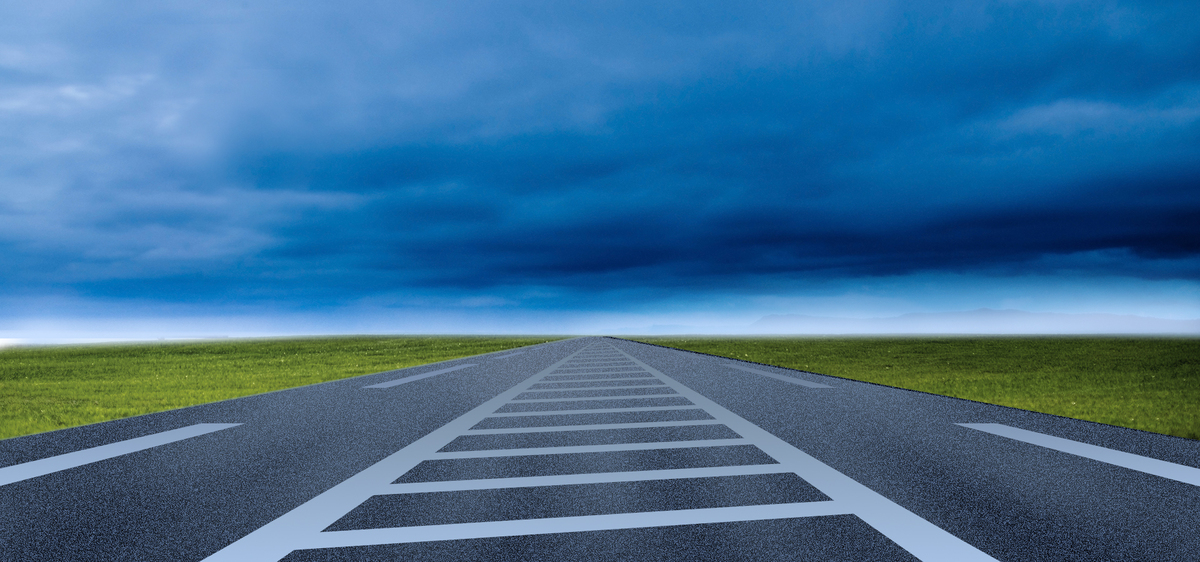

In [21]:
im = Image.open('example.jpg')
display(im)

In [29]:
img = np.array(im)
h, w, c = img.shape
print(img.shape)

(562, 1200, 3)


In [30]:
img = img.reshape(-1, 3)
img.shape

(674400, 3)

In [31]:
print(img)

[[130 172 222]
 [127 171 220]
 [130 174 223]
 ...
 [ 53  68  89]
 [ 38  48  60]
 [ 25  31  43]]


In [ ]:
# GaussianMixture
# gmm = GaussianMixture(...)
# gmm.fit(img)
# pred = gmm.predict(img)

In [ ]:
# pred = pred.reshape(h, w)
# result = np.zeros((h, w, c))
# result[pred == 0, :] = [255, 255, 0]
# ...

### 3  在Olivetti人脸数据集上训练高斯混合模型

In [1]:
from sklearn.datasets import fetch_olivetti_faces

olivetti = fetch_olivetti_faces()

In [2]:
print(olivetti.DESCR)

.. _olivetti_faces_dataset:

The Olivetti faces dataset
--------------------------

`This dataset contains a set of face images`_ taken between April 1992 and 
April 1994 at AT&T Laboratories Cambridge. The
:func:`sklearn.datasets.fetch_olivetti_faces` function is the data
fetching / caching function that downloads the data
archive from AT&T.

.. _This dataset contains a set of face images: https://cam-orl.co.uk/facedatabase.html

As described on the original website:

    There are ten different images of each of 40 distinct subjects. For some
    subjects, the images were taken at different times, varying the lighting,
    facial expressions (open / closed eyes, smiling / not smiling) and facial
    details (glasses / no glasses). All the images were taken against a dark
    homogeneous background with the subjects in an upright, frontal position 
    (with tolerance for some side movement).

**Data Set Characteristics:**

    =================   =====================
    Classes    

In [3]:
olivetti.target

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  3,  3,  3,  3,
        3,  3,  3,  3,  3,  3,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  5,
        5,  5,  5,  5,  5,  5,  5,  5,  5,  6,  6,  6,  6,  6,  6,  6,  6,
        6,  6,  7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  8,  8,  8,  8,  8,
        8,  8,  8,  8,  8,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9, 10, 10,
       10, 10, 10, 10, 10, 10, 10, 10, 11, 11, 11, 11, 11, 11, 11, 11, 11,
       11, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12, 13, 13, 13, 13, 13, 13,
       13, 13, 13, 13, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 15, 15, 15,
       15, 15, 15, 15, 15, 15, 15, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16,
       17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 18, 18, 18, 18, 18, 18, 18,
       18, 18, 18, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 20, 20, 20, 20,
       20, 20, 20, 20, 20, 20, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 22,
       22, 22, 22, 22, 22